# Quiz 2：多模態深度學習神經網路（35 分）

**蘇芯儀 / Sharon0726**

本 Notebook 已執行並顯示 Colab T4 訓練保存的真實結果。訓練程式與推論程式完整附在同目錄；需要重訓請使用 `MMIP_Week5_Colab.ipynb`，本 Notebook 重跑只讀取結果，不重新訓練。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week5 with results/ present.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))
def source(name): display(Markdown('```python\n'+Path(name).read_text(encoding='utf-8')+'\n```'))


## 1. 影像與文字訓練資料（5 分）

Flickr8k 沿用 Week4 的 6000/1000/1091 影像切分。每張圖取第一句 caption；原始圖文配對標記 1，同集合內一對一打亂的文字標記 0。排除自身 ID 及相同文字。每張圖與每句話正負各一次，避免單一模態的分布洩漏標籤。不同照片也可能具有相容描述，因此這是原始配對分類，負例不是人類認定的語意錯誤。

In [2]:
pairs=pd.read_csv(R/'multimodal_pairs.csv')
display(pairs.groupby(['split','label']).size().unstack())
for split,part in pairs.groupby('split'):
    assert (part.groupby(['image_id','label']).size()==1).all()
    assert (part.groupby(['text_id','label']).size()==1).all()
print('PASS: each input appears once under each label in its split.')
display(pairs.head(6))

label,0,1
split,,
test,1091,1091
train,6000,6000
validation,1000,1000


PASS: each input appears once under each label in its split.


,split,image_id,text_id,label
0,train,4659,4659,1
1,train,4659,4315,0
2,train,6248,6248,1
3,train,6248,7187,0
4,train,6861,6861,1
5,train,6861,3515,0


## 2. 雙 Backbone 特徵融合（10 分）

影像：ResNet18 512 維或 ViT-Tiny 192 維。文字：MiniLM 384 維，attention-mask mean pooling + L2 normalize。凍結兩個 backbone，分別投影為 256 維的 u、v，再融合 `[u,v,|u-v|,u*v]`，MLP 輸出二類 logits。

In [3]:
src=Path('models.py').read_text(encoding='utf-8')
display(Markdown('```python\n'+src[src.index('class FusionModel'):]+'\n```'))
for kind in ['resnet','vit','minilm']: display(read('features_'+kind+'.json'))

```python
class FusionModel(nn.Module):
    def __init__(self,image_dim,text_dim=384,hidden=256,mode='fusion'):
        super().__init__(); self.mode=mode
        self.image=nn.Sequential(nn.LayerNorm(image_dim),nn.Linear(image_dim,hidden),nn.ReLU())
        self.text=nn.Sequential(nn.LayerNorm(text_dim),nn.Linear(text_dim,hidden),nn.ReLU())
        self.head=nn.Sequential(nn.Linear(hidden*(4 if mode=='fusion' else 1),hidden),nn.ReLU(),nn.Dropout(.3),nn.Linear(hidden,2))
    def forward(self,images,texts):
        u,v=self.image(images),self.text(texts)
        fused=torch.cat([u,v,(u-v).abs(),u*v],dim=-1) if self.mode=='fusion' else (u if self.mode=='image' else v)
        return self.head(fused)

```

{'kind': 'resnet',
 'dataset_revision': '81fc5f3a41274c80f17b0406426d57cac57ce6fb',
 'model_revision': 'ImageNet pretrained; timm 1.0.15 / torchvision V1',
 'transform': 'resize224 + ImageNet/model normalization',
 'shape': [8091, 512],
 'extraction_seconds': 44.23493128100017,
 'frozen': True}

{'kind': 'vit',
 'dataset_revision': '81fc5f3a41274c80f17b0406426d57cac57ce6fb',
 'model_revision': 'ImageNet pretrained; timm 1.0.15 / torchvision V1',
 'transform': 'resize224 + ImageNet/model normalization',
 'shape': [8091, 192],
 'extraction_seconds': 43.57219768499999,
 'frozen': True}

{'model': 'sentence-transformers/all-MiniLM-L6-v2',
 'revision': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41',
 'max_length': 128,
 'text_sha256': '1eb90008a0d6d9adf22a2da65cb82f76fc775046d360b3ba9b8beb6c5f364ef9',
 'shape': [8091, 384],
 'extraction_seconds': 3.363258554999902,
 'frozen': True,
 'pooling': 'attention-mask mean; L2 normalize'}

## 3. 訓練與測試推論（5 分）

25 epochs、AdamW lr=0.001、batch=128、cross-entropy，以 validation Macro-F1 選 checkpoint。完整程式在 [quiz2_multimodal.py](quiz2_multimodal.py)。以下固定前三張測試圖各展示正／負配對，不挑例。

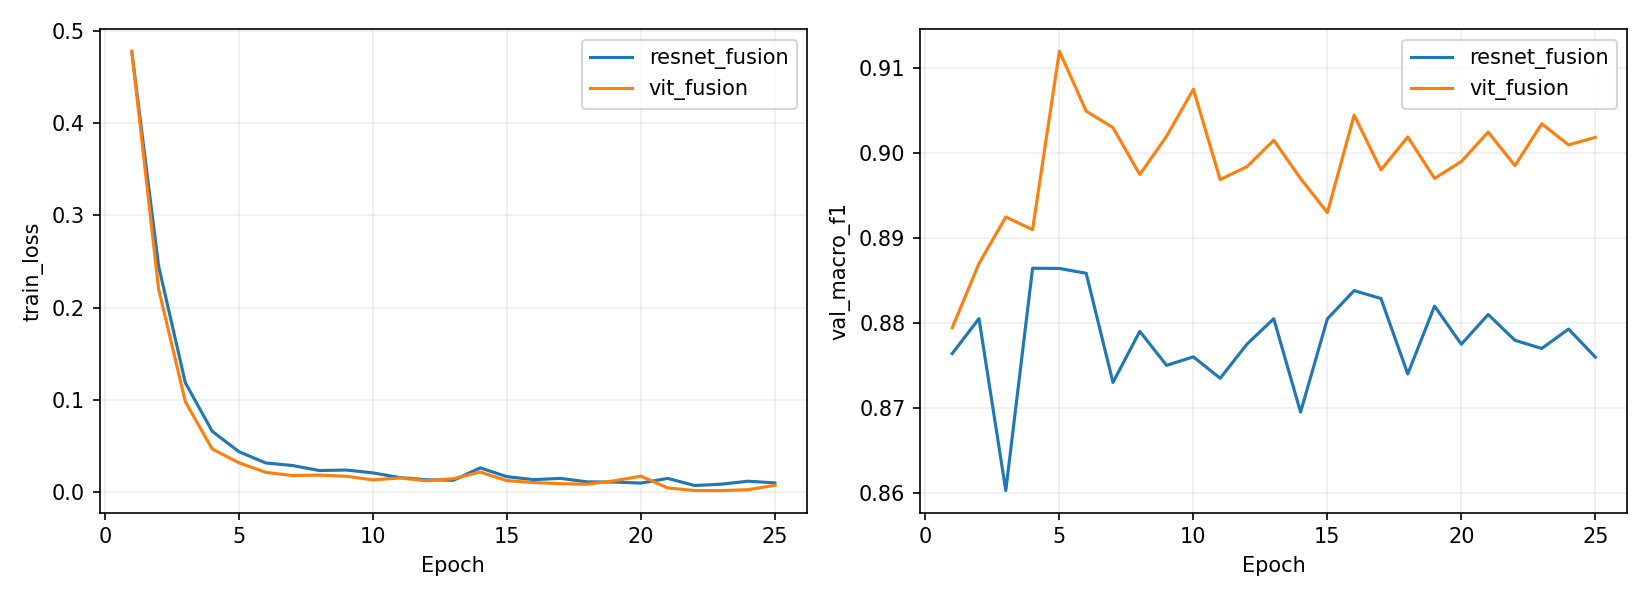

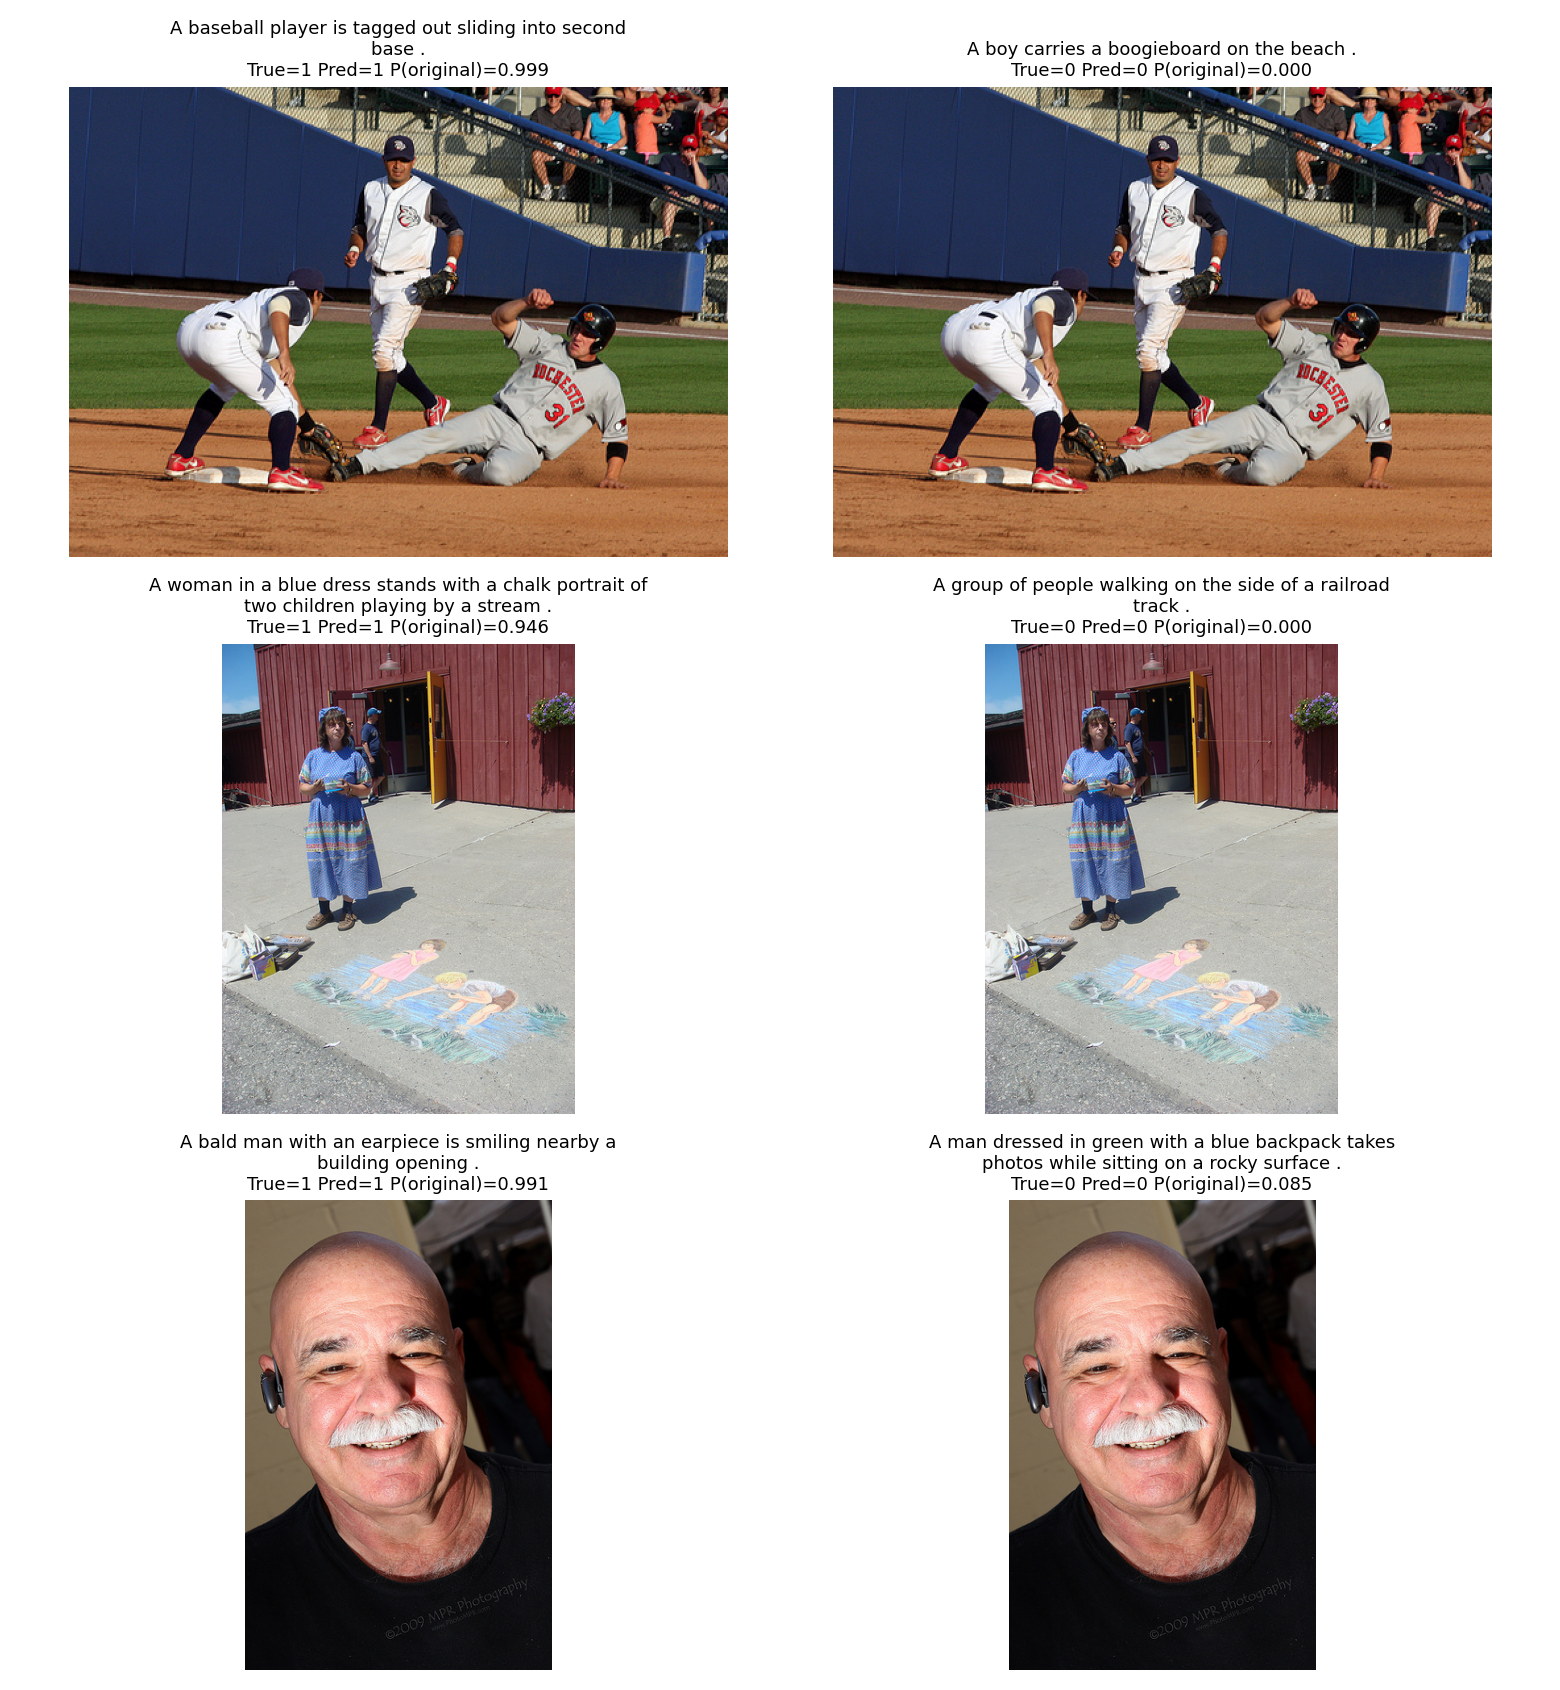

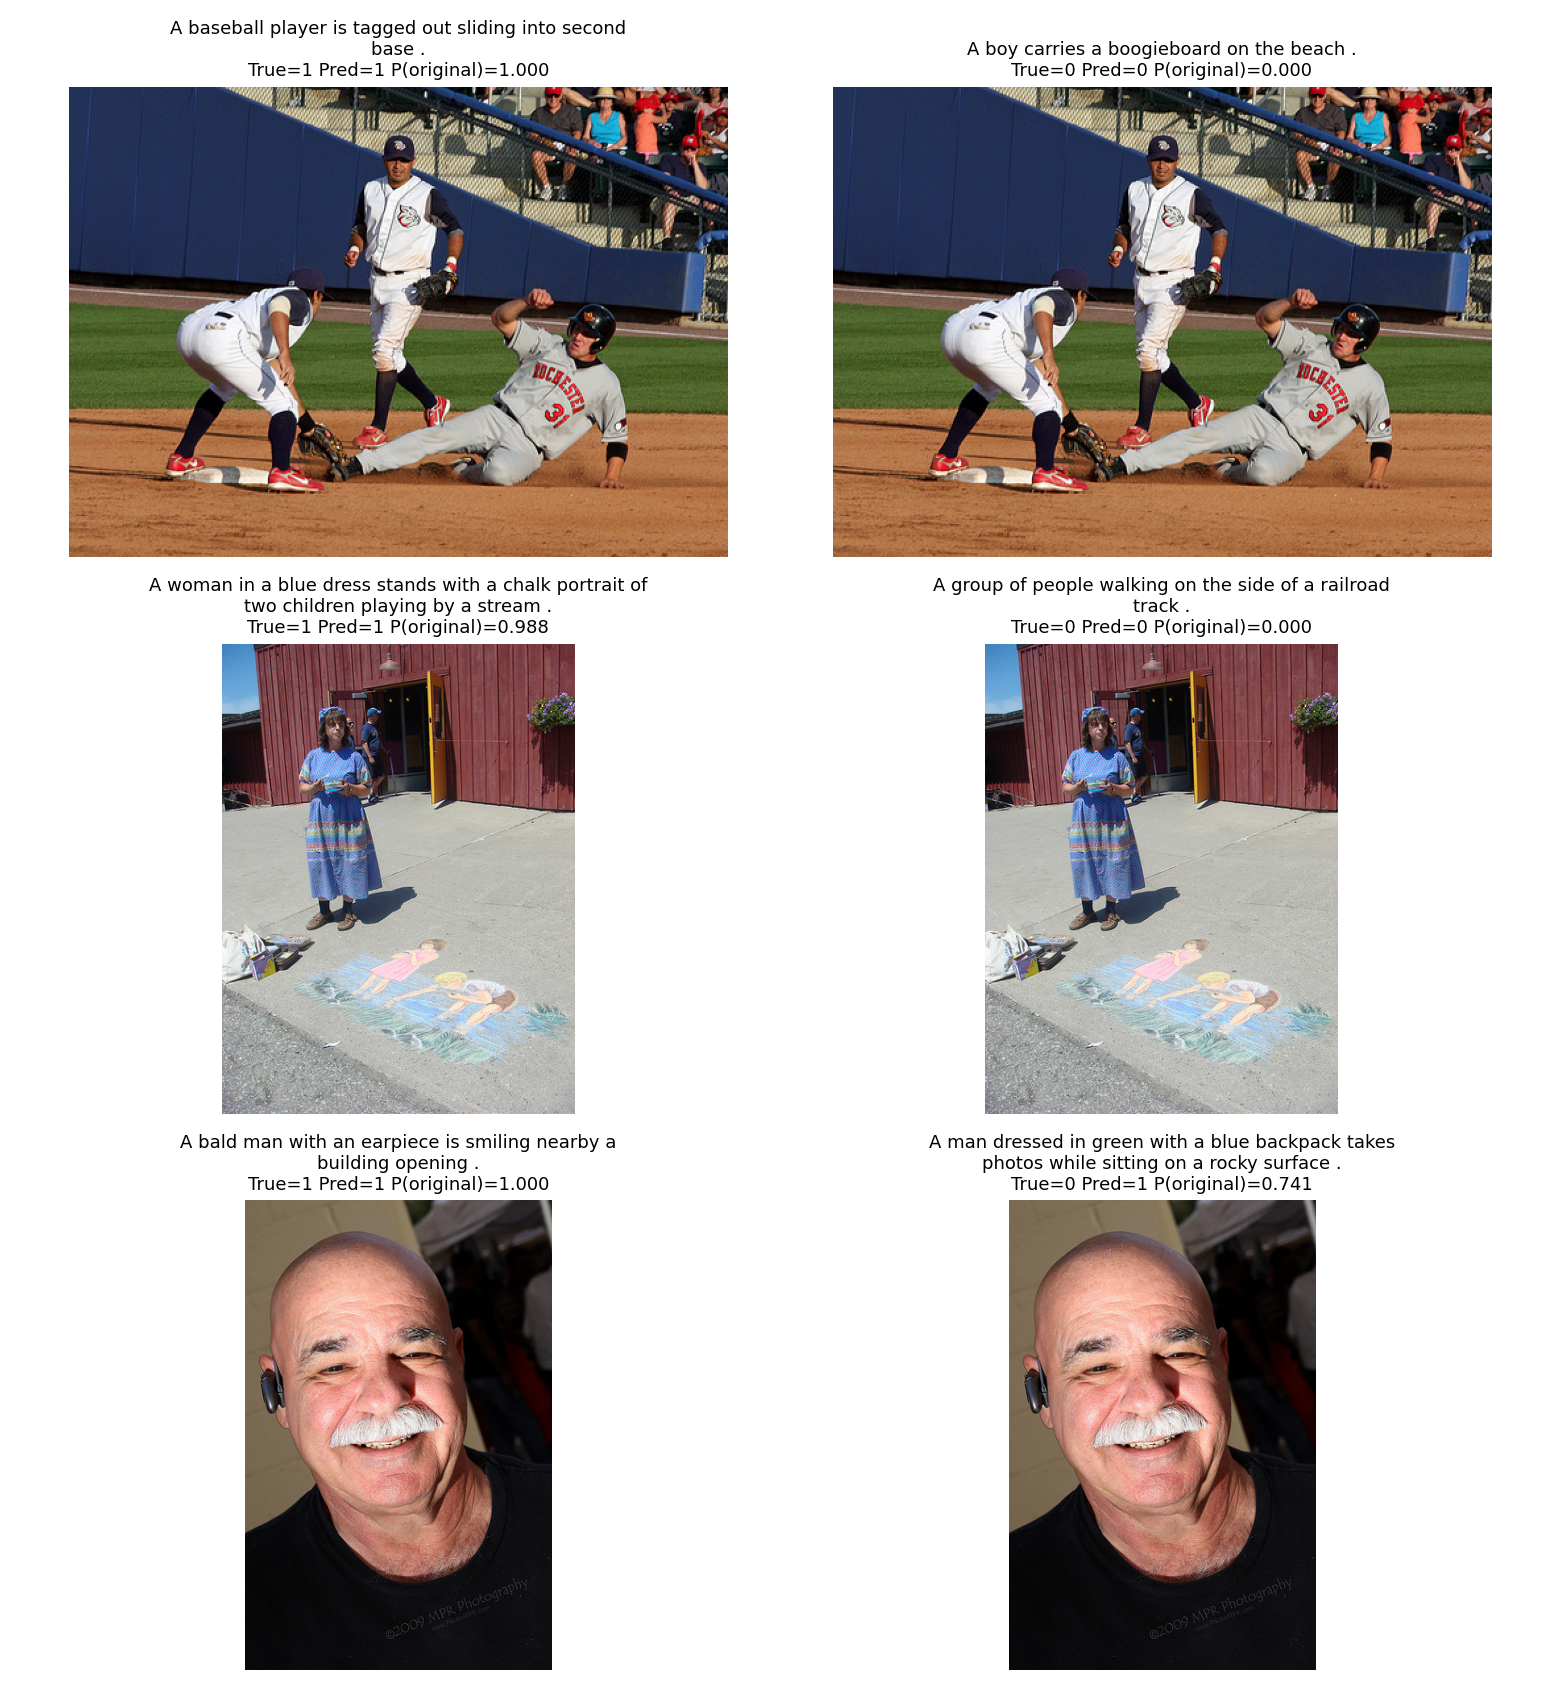

,split,image_id,text_id,label,prediction,p_0,p_1
0,test,2800,2800,1,1,0.000097,9.999026e-01
1,test,2800,6521,0,0,1.000000,1.132279e-10
2,test,79,79,1,1,0.011578,9.884219e-01
3,test,79,4535,0,0,0.999955,4.506926e-05
4,test,5490,5490,1,1,0.000002,9.999982e-01
5,test,5490,7744,0,1,0.259498,7.405016e-01


In [4]:
show('multimodal_learning.png')
show('multimodal_resnet.png')
show('multimodal_vit.png')
display(pd.read_csv(R/'predictions/multimodal_vit_fusion.csv').head(6))

## 4. 更換 Backbone、重訓與比較（15 分）

實際比較 ResNet18+MiniLM 與 ViT-Tiny+MiniLM，同一配對、超參數、切分與指標；使用原始 ImageNet 特徵，不沿用 Quiz 1 的微調權重。另訓練 image-only / text-only 各 10 epochs 檢查平衡設計，它們不是相同預算的架構競賽。

,model,best_epoch,train_seconds,trainable_parameters,image_backbone,text_backbone,mode,accuracy,macro_f1,macro_precision,macro_recall,auc
0,resnet_fusion,4,12.080729,494594,resnet,all-MiniLM-L6-v2,fusion,0.870761,0.870500,0.873777,0.870761,0.942096
1,vit_fusion,5,11.969467,412034,vit,all-MiniLM-L6-v2,fusion,0.890926,0.890864,0.891816,0.890926,0.951560
2,resnet_image,1,3.997563,297986,resnet,all-MiniLM-L6-v2,image,0.500000,0.494431,0.500000,0.500000,0.500000
3,resnet_text,1,4.253144,297986,resnet,all-MiniLM-L6-v2,text,0.500000,0.499886,0.500000,0.500000,0.500000


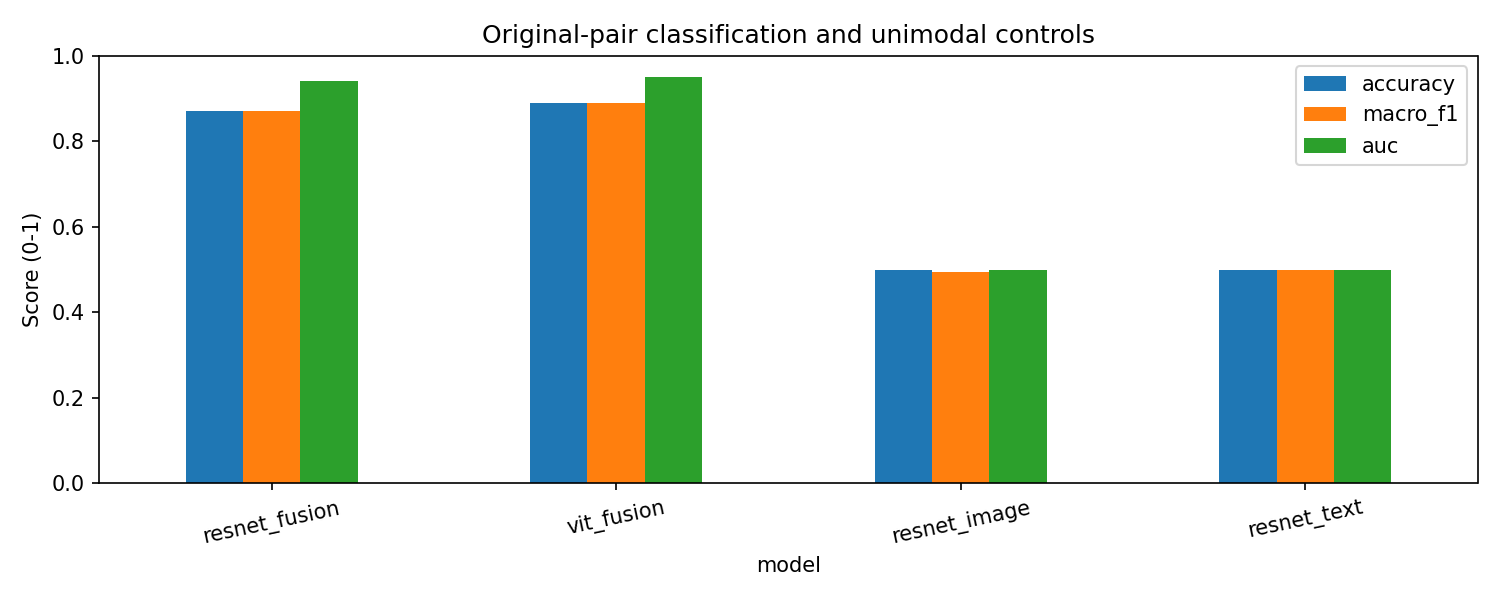

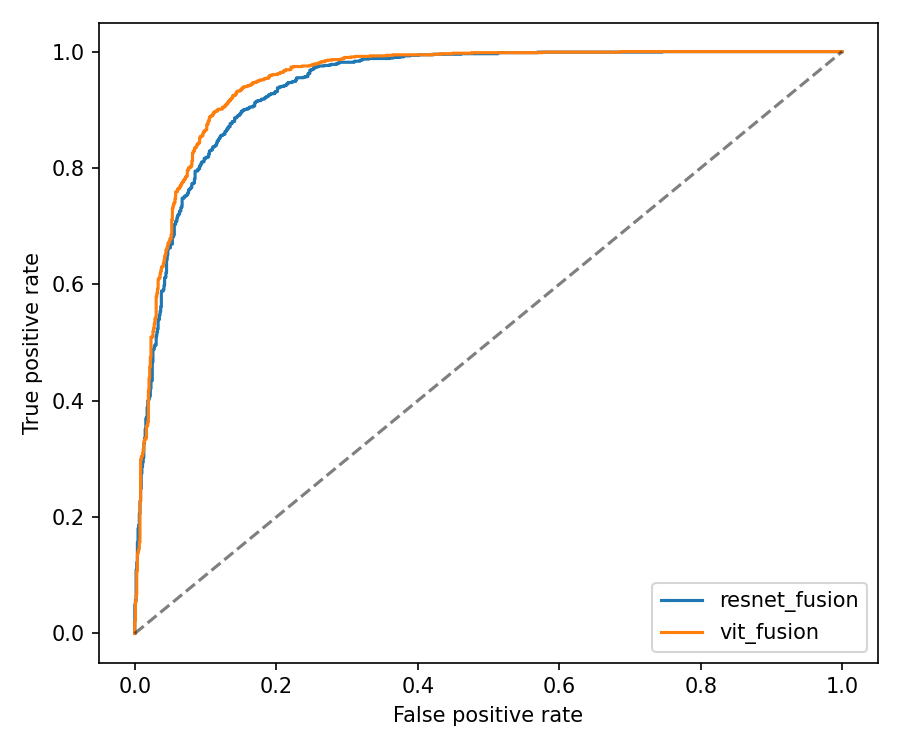

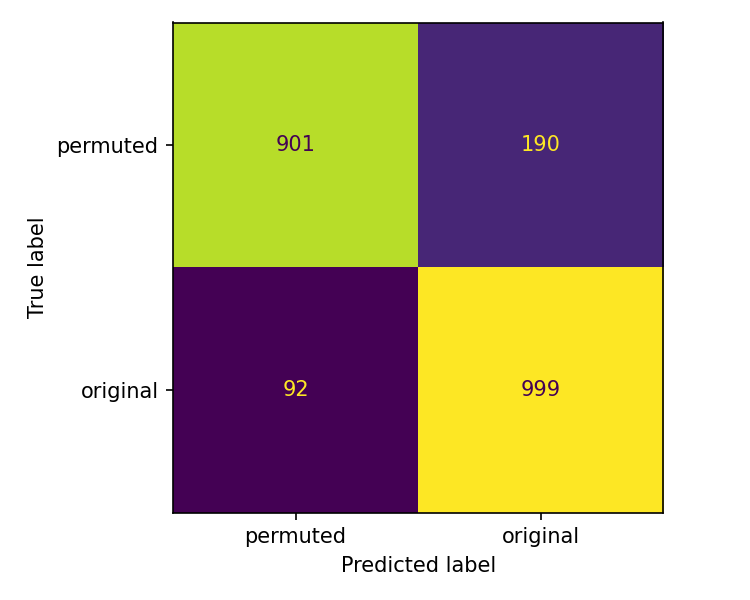

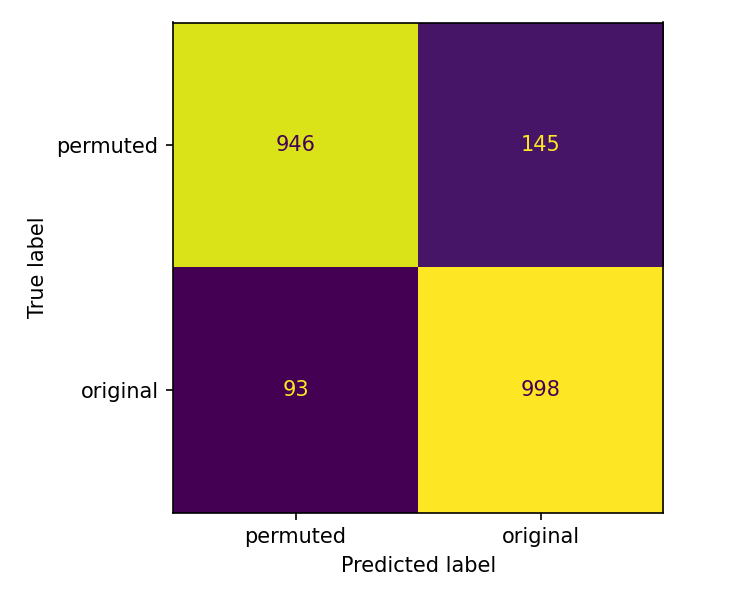

融合組合 Macro-F1 較高：vit_fusion，0.8909


In [5]:
d=pd.read_csv(R/'multimodal_metrics.csv')
display(d)
show('multimodal_comparison.png')
show('multimodal_roc.png')
show('multimodal_confusion_resnet_fusion.png')
show('multimodal_confusion_vit_fusion.png')
best=d[d['mode']=='fusion'].sort_values('macro_f1',ascending=False).iloc[0]
print(f'融合組合 Macro-F1 較高：{best.model}，{best.macro_f1:.4f}')

ROC-AUC 使用連續正例機率，不能用 hard label 代替。單模態輸入的正負分布完全相同，test Accuracy 應為 0.5；Macro-F1 仍受預測正負比例影響。模型機率未校準，也不是新圖片描述是否真實的判定工具。見 [完整報告](REPORT.md)。